# Chapter 11: Attention Mechanisms and Transformers

# 11.1 Queries, Keys, and Values
* CNNs and RNNs typically rely on input being of a well-defined size
    * CNNs being tuned on ImageNet $224 \times 224$ pixels
    * RNNs input sizes are well-defined and fixed (even if they can process sequences of any length)
* Sequences of variable size can be addressed by sequentially processing one token at a time, or by specially designed convolutional kernels (Kalchbrenner et al. 2014)
* Long sequences, it can become difficult yo keep track of everything that has already been generated/viewed by the network. Explicit tracking heuristics offer limited benefits only
* Compare to database $\mathcal{D}$
    * Collection of keys ($k$) and values ($v$)
    * We can operate on $\mathcal{D}$ with exact query ($q$)
    * Note, we can make approximate or exact queries
* Takeaways from database sidenote:
    * We can design queries $q$ that operate on $(k, v)$ pairs in a manner as to be valid regardless of the database size
    * Same query can receive different answers, according to the contents of the database
    * The "code" being executed for operating on a large state space (the database) can be quite simple (e.g. exact match, approximate match, top-k)
    * There is no need to compress or simplify the database to make operations effective
* Consider the database $\mathcal{D} \stackrel{\textrm{def}}{=} \{(\mathbf{k}_1, \mathbf{v}_1), \ldots (\mathbf{k}_m, \mathbf{v}_m)\}$ of $m$ tuples of keys and values, where $\mathbf{q}$ denotes query $\alpha(\mathbf{q}, \mathbf{k}_i) \in \mathbb{R}$ ($i = 1, \ldots, m$) are scalar attention weights
$$\textrm{Attention}(\mathbf{q}, \mathcal{D}) \stackrel{\textrm{def}}{=} \sum_{i=1}^m \alpha(\mathbf{q}, \mathbf{k}_i) \mathbf{v}_i$$
* This operation is typically referred to as _attention pooling_
* Some special cases, characteristics, properties
    * The attention weights $\alpha(\mathbf{q})$ are non-negative. In this case, the output of the attention mechanism is contained in the convex cone spanned by values $v_i$
    * Weights $\alpha(\mathbf{q})$ form a convex comvination i.e. $\sum_i \alpha(\mathbf{q}) = 1$ and $\alpha(\mathbf{q}) \geq 0$ for all $i$
    * In the event that one of the weights $\alpha(\mathbf{q})=1$ and all other weights $=0$, this is similar to a traditional database query
    * In the event that all weights are equal, $\alpha(\mathbf{q}) = \frac{1}{m}$ for all $i$, this amounts fo averaging across the entire database, a.k.a. average pooling in deep learning terminology
* To ensure weights sum up to $1$, we can normalize them via
    $$\alpha(\mathbf{q}, \mathbf{k}_i) = \frac{\alpha(\mathbf{q}, \mathbf{k}_i)}{{\sum_j} \alpha(\mathbf{q}, \mathbf{k}_j)}.$$
    * To ensure weights are non-negative as well (along with normalized to 1), we cna resort to exponentiation and softmax operation. This operation is differentiable and its gradient never vanishes (im guessing buy each token/vector (along with KQV matricies ) having paths from loss signal from all other tokens, so unlikely that all gradient signals to it get cut off)
    $$\alpha(\mathbf{q}, \mathbf{k}_i) = \frac{\exp(a(\mathbf{q}, \mathbf{k}_i))}{\sum_j \exp(a(\mathbf{q}, \mathbf{k}_j))}. $$

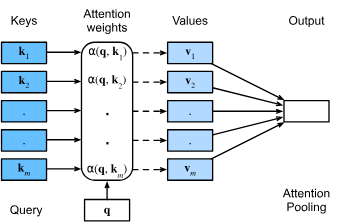

What bulk of modern attention research follows. Is possible to design non-differentiable attention model that can be trained with RL, but won't be covered in this textbook. 

* Convienent Factors
    * Actual code for executing keys, values, queries can be quite concise, which is desirable for a network layer since it does not require many parameters to learn
    * Attentino can operate on arbitrarily large databases without the need to change the way attention pooling operation is performed

In [3]:
import torch
from d2l import torch as d2l

### 11.1.1 Visualization
* Attentino can be "intuitive" in that large attention weights will be given more "attention", and serves as a way for the model to select components of relevance 
* May want to visualize effect on given set of keys when applying variety of different queries
* Define a `show_heatmaps` function 
    * Does not make a matrix (of attention weights) as its input
    * Takes a tensor w/ 4 axes, allowing for an array of different queries and weights
    * (number of rows for display, number of columns for display, number of queries, number of keys)
* Perform quick sanity check with identity matrix where attention weight is 1 only if query and key are the same

In [4]:
def show_heatmaps(matrices, xlabel, ylabel, titles=None, figsize=(2.5, 2.5), cmap='Reds'):
    """Show heatmaps of matrices.
    Required Args:
        matrices: A 4D tensor of shape (num_rows, num_cols, height, width) containing the matrices to be displayed.
        xlabel: The label for the x-axis.
        ylabel: The label for the y-axis.
    """
    d2l.use_svg_display()
    num_rows, num_cols, _, _ = matrices.shape
    fig, axes = d2l.plt.subplots(num_rows, num_cols, figsize=figsize,
                                 sharex=True, sharey=True, squeeze=False)
    for i, (row_axes, row_matrices) in enumerate(zip(axes, matrices)):
        for j, (ax, matrix) in enumerate(zip(row_axes, row_matrices)):
            pcm = ax.imshow(matrix.detach().numpy(), cmap=cmap)
            if i == num_rows - 1:
                ax.set_xlabel(xlabel)
            if j == 0:
                ax.set_ylabel(ylabel)
            if titles:
                ax.set_title(titles[j])
    fig.colorbar(pcm, ax=axes, shrink=0.6)

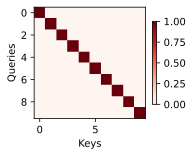

In [5]:
# Sanity check of show_heatmaps function with Identity matrix
attention_weights = torch.eye(10).reshape((1, 1, 10, 10))
show_heatmaps(attention_weights, xlabel='Keys', ylabel='Queries')

### 11.1.2 Summary
* Attention allows us to aggregate data from many key-value pairs
* Attention provides differentiable method for a neural network to select elements from set and construct an associated weighted sum over representations

### 11.1.3 Exercises
1. Suppose that you wanted to reimplement approximate (key, query) matches as used in classical databases, which attention function would you pick? 
1. Suppose that the attention function is given by $a(\mathbf{q}, \mathbf{k}_i) = \mathbf{q}^\top \mathbf{k}_i$ and that $\mathbf{k}_i = \mathbf{v}_i$ for $i = 1, \ldots, m$. Denote by $p(\mathbf{k}_i; \mathbf{q})$ the probability distribution over keys when using the softmax normalization. Prove that $\nabla_{\mathbf{q}} \mathop{\textrm{Attention}}(\mathbf{q}, \mathcal{D}) = \textrm{Cov}_{p(\mathbf{k}_i; \mathbf{q})}[\mathbf{k}_i]$.
1. Design a differentiable search engine using the attention mechanism. 
1. Review the design of the Squeeze and Excitation Networks Hu.Shen.Sun.2018 and interpret them through the lens of the attention mechanism. 


Exercise #1
* Require binary pooling where only returns 1 if weight in first place is 1 or very close to it
* Realistically, would probably be within some numerical tolerance/band close to 1

Exercise #2
* $\textrm{Cov}_{p(\mathbf{k}_i; \mathbf{q})}[\mathbf{k}_i]$ refers to covariance matrix of key vectors $k_i$, where each $k_i$ is weighted according to softmax probability distribution determined over query $q$
    * Semicolon indicates probability distribution over $k_i$, parameterized by $q$
    * $\textrm{Cov}(X, Y)$ measures how two scalar variables $X, Y$ move together
    * $\textrm{Cov}([k_i])$ measures how all components of a vector $k_i$ move together. The probability distribution subscript $p(k_i; q)$ indicates which probability distribution it is over (i.e. given a query vector) 
* Define attention function like: $a(\mathbf{q}, \mathbf{k}_i) = \mathbf{q}^\top \mathbf{k}_i$ and define probability distribution over keys with softmax normalization to get: 
$$ p(k_i;q) = \frac{\exp{(q^\top k_i)}}{\sum_j^m \exp{(q^\top k_j)}}$$
* Recall from earlier and how attention works and $k_i = v_i$ as given by problem: 
$$\textrm{Attention}(\mathbf{q}, \mathcal{D}) \stackrel{\textrm{def}}{=} \sum_{i=1}^m \alpha(\mathbf{q}, \mathbf{k}_i) \mathbf{v}_i$$
$$\textrm{Attention}(\mathbf{q}, \mathcal{D}) = \sum_{i=1}^m p_i v_i = \sum_{i=1}^m p_i k_i = \sum_{i=1}^m p(k_i; q) k_i = \sum_{i=1}^m \frac{\exp{(q^\top k_i)}}{\sum_j^m \exp{(q^\top k_j)}} k_i$$
* Take gradient w.r.t. q to get:
$$ \nabla\textrm{Attention}(\mathbf{q}, \mathcal{D}) = \sum_i^m (k_i) \left( p_i k_i - p_i \left(\sum_j^m k_j p_j \right) \right)$$
$$ \nabla\textrm{Attention}(\mathbf{q}, \mathcal{D}) = \sum_i^m \left(p_i k_i k_{i}^{\top} \right) + \mu \mu^\top$$
$$ \nabla\textrm{Attention}(\mathbf{q}, \mathcal{D}) = \mathbb{E}_{p(k_i;q)}[k_i k_i^\top] - \mathbb{E}_{p(k_i;q)}[k_i]\mathbb{E}_{p(k_i;q)}[k_i^\top]$$
$$  \textrm{Cov}(X, Y) = \mathbb{E}[XY] - \mathbb{E}[X]\mathbb{E}[Y]$$
$$ \textrm{Cov}_{p(k_i;q)}[k_i] = \mathbb{E}[k_i k_i^\top] - \mathbb{E}[k_i]\mathbb{E}[k_i]^\top$$
* Where $\mu \equiv \sum_i^m p_i k_i$
* Detailed work avaiable in my OneNote Chapter 11 section
* Keep in mind covariance of a vector ($k_i$) is a matrix

Exercise #3
* q: representation of user query
* k: representation of key corresponding to value 
* v: value to be returned to user
* Attention based differentiable search engine would return value based on how well it matches. Can also add mechanism to return nothing if highest weight is too low

Exercise #4
* COME BACK LATER
# COME BACK LATER FOR EXERCISE #4

# 11.2 Attention Pooling by Similarity
* Skip. Textbook said that this is optional background

### 11.2.1 Kernels and Data

### 11.2.2 Attention Pooling via Nadaraya–Watson Regression

### 11.2.3 Adapting Attention Pooling

### 11.2.4 Summary

### 11.2.5 Exercises
1. Parzen windows density estimates are given by $\hat{p}(\mathbf{x}) = \frac{1}{n} \sum_i k(\mathbf{x}, \mathbf{x}_i)$. Prove that for binary classification the function $\hat{p}(\mathbf{x}, y=1) - \hat{p}(\mathbf{x}, y=-1)$, as obtained by Parzen windows is equivalent to Nadaraya--Watson classification. 
1. Implement stochastic gradient descent to learn a good value for kernel widths in Nadaraya--Watson regression. 
    1. What happens if you just use the above estimates to minimize $(f(\mathbf{x_i}) - y_i)^2$ directly? Hint: $y_i$ is part of the terms used to compute $f$.
    1. Remove $(\mathbf{x}_i, y_i)$ from the estimate for $f(\mathbf{x}_i)$ and optimize over the kernel widths. Do you still observe overfitting?
1. Assume that all $\mathbf{x}$ lie on the unit sphere, i.e., all satisfy $\|\mathbf{x}\| = 1$. Can you simplify the $\|\mathbf{x} - \mathbf{x}_i\|^2$ term in the exponential? Hint: we will later see that this is very closely related to dot product attention. 
1. Recall that mack1982weak proved that Nadaraya--Watson estimation is consistent. How quickly should you reduce the scale for the attention mechanism as you get more data? Provide some intuition for your answer. Does it depend on the dimensionality of the data? How?


# 11.3 Attention Scoring Functions

In [6]:
import math
import torch
from torch import nn
from d2l import torch as d2l

### 11.3.1 Dot Product Attention
* Recall attention function without exponentiation from Gaussian kernel:
$$ a(q, k_i) = -\frac{1}{2} \lVert q - k_i \rVert^2 = q^\top k_i - \frac{1}{2}\lVert k_i \rVert^2 - \frac{1}{2}\lVert q \rVert^2 $$
* Notice how the final term is only dependent on $q$ — thus will be identical for all $(q, k_i)$ pairs. Thus, normalizing with softmax will get rid of the term (constant term factored out from exponent from both numerator and denominator)
* Note — both BatchNorm and LayerNorm lead to activations that have well-bounded and constant norms $\lVert k_i \rVert$
    * Thus, we can drop it from attention formula without worry (same reason as above, once normalized will cancel from numerator and demoninator)
* At this point: $ a(q, k_i) = -\frac{1}{2} \lVert q - k_i \rVert^2 = q^\top k_i $
    * We need to keep the magnitude of the arguments of exponential function under control to over/underflow
    * Assume all elements of query and key vector $(q, k \in \mathbb{R}^d)$ are independent and identically drawn random variables from a distribution of $\mu = 0$ and $\sigma^2 = 1$ (zero mean, unit variance)
        * Means: $\mathbb{E}(XY) = \mathbb{E}(X)\mathbb{E}(Y) + \textrm{Cov}(X, Y) = \mathbb{E}(X)\mathbb{E}(Y)$. Since random variables (the elements of the query and key vectors) are assumed to be independent, their covariance is 0
        * Variances: $ \textrm{Var}(XY) = \mathbb{E}\left((XY)^2\right) - \left(\mathbb{E}(XY)\right)^2 = \textrm{Var}(X)\textrm{Var}(Y) + \textrm{Var}(X)[\mathbb{E}(y)]^2 + \textrm{Var}(Y)[\mathbb{E}(X)]^2 = \textrm{Var}(X)\textrm{Var}(Y) = 1$, since we assumed zero means and unit variance for $X, Y$
    * Thus, the mean of the dot product $q^\top k_i$ will be $0$, but the variance would be $d$. Thus, we divide $q^\top k_i$ by $\sqrt{d}$ to get unit variance. Motivation/intuition is shown below: 
        * $\text{Var}(Z) = \mathbb{E}(Z^2) - (\mathbb{E}(Z))^2 = d$, by dividing $Z$ by $\sqrt{d}$, so we get: $\mathbb{E}\!\left((Z / \sqrt{d})^2\right) = \frac{\mathbb{E}(Z^2)}{d} = 1$ where $Z = XY$
* Normalizing by softmax, we get: 
    * $\alpha(q, k_i) = \text{softmax}(a(q, k_i)) = \frac{\exp{\left(q^\top k_i / \sqrt{d}\right)}}{\left( \sum_{j=1} \exp{q^\top k_j / \sqrt{d}} \right)} $

### 11.3.2 Convenience Functions
* Need a few functinos to make attention efficient to deploy, such as dealing with: 
    * Deal with sequences of different lengths (that may end up in the same minibatch) - common in NLP tasks
    * Tools for efficient evaluation on minibatches (batch matrix multiplication)

### Masked Softmax Operations
* Sequence models, such as text strings in NLP w/ attention. 
* Would have to deal with sequences of different lengths that could be in the minibatch
    * Necessitates padding w/ dummy tokens for shorter sequences that do not varry any meaning
* We do not want blanks to limit $\sum_{i=1}^n \alpha(q, k_i)$ to $\sum_{i=1}^l \alpha(q, k_i) v_i for $l \leq n$
    * This is a common problem, and is called "masked softmax attention"
* Often dealth with by setting values of $v_i = 0$ for $i > l$ and attention weights to a large magnitude negative number (e.g. $-10^6) to make their gradient and value contributions vanish in practice (recall exponentaion during softmax of attention weights). This is preferable since linear algebra kernels and operators are optimized for GPUs and it is better to have some wasteful matrix computation than have conditional statements. It is implemented below:  

In [19]:
def masked_softmax(X, valid_len):
    """
    Perform softmax operation by masking elements on their last axis 

    Args:
        X: 3D input tensor 
        valid_len: 1D or 2D tensor
    """
    def _sequence_mask(X, valid_len, value=0):
        max_len = X.size(1)
        mask = torch.arange(end=max_len, dtype=torch.float32, device=X.device)[None, :] < valid_len[:, None]

        X[~mask] = value
        return X
    
    if valid_len is None:
        return nn.functional.softmax(X, dim=-1)
    else:
        shape = X.shape
        if valid_len.dim() == 1:
            valid_lens = torch.repeat_interleave(valid_len, shape[1])
        else:
            valid_lens = valid_lens.reshape(-1)
        X = _sequence_mask(X.reshape(-1, shape[-1]), valid_lens, value=-1e6)
        return nn.functional.softmax(X.reshape(shape), dim=-1)


In [21]:
# Demo where minibatch is two examples of size 2x4 and valid lengths are 2, 3 respectively
X = torch.rand(2, 2, 4)
masked_softmax(X, torch.tensor([2, 3]))

tensor([[[0.4949, 0.5051, 0.0000, 0.0000],
         [0.7045, 0.2955, 0.0000, 0.0000]],

        [[0.4988, 0.2517, 0.2496, 0.0000],
         [0.3397, 0.3252, 0.3351, 0.0000]]])

### Batch Matrix Multiplication
* Another commonly used operation is to multiply batches of matricies by one another
* Useful when we have minibatches of queries, keys, and values
* Assume that: 
    * $ Q = [Q_1, Q_2, ... , Q_n] \in \mathbb{R}^{n\times b \times c}$
    * $ K = [K_1, K_2, ... , K_n] \in \mathbb{R}^{n\times b \times c}$
* Batch Matrix Multiplication (BMM) computes elementwise matrix multiplication product: 
    * $\text{BMM}(Q, K) = [Q_1 K_1, Q_2 K_2, ... , Q_n K_n] \in \mathbb{R}^{n \times a \times c}$

In [22]:
Q = torch.ones((2, 3, 4))
K = torch.ones((2, 4, 6))
d2l.check_shape(torch.bmm(Q, K), (2, 3, 6))

### 11.3.3 Scaled Dot Product Attention
* Recall scaled dot product attetion from earlier section 11.1: $ a(q, k_i) = q^\top k_i / \sqrt{d} $
    * Generally requires that query and key have same vector dimension $d$
    * Note - this can be sidestepped by replacing with $ a(q, k_i) = q^\top M k_i / \sqrt{d} $ where $M$ is a matrix chosen to translate between both spaces
    * For now, will be assuming query and key are of the same dimension 
* Think in terms of minibatches for efficiency, such as calculating attention for $n$ queries and $m$ key-value pairs where the queries and keys are of length $d$ and values are of lenvth $v$
    * $Q\in \mathbb{R}^{n\times d}$
    * $K\in \mathbb{R}^{m\times d}$
    * $V\in \mathbb{R}^{m\times v}$
    * $ \text{softmax}\left( \frac{QK^\top}{\sqrt{d}} \right) V \in \mathbb{R}^{n\times v}$

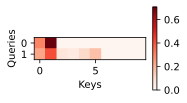

In [27]:
class DotProductAttention(nn.Module):
    """Scaled dot product attention."""
    def __init__(self, dropout):
        super().__init__()
        self.dropout = nn.Dropout(dropout)


    def forward(self, queries, keys, values, valid_lens=None):
        """
        Query Shape:      (batch_size, # of queries, d)
        Key Shape:        (batch_size, # of key-value pairs, d)
        Value Shape:      (batch_size, # of key-value pairs, value dim)
        Valid Lens Shape: (batch_size,) or (batch_size, # of queries)
        """
        d = queries.shape[-1]
        # Swap the last two dimensions of keys with keys.transpose(1, 2) for matrix multiplication 
        # dimension match for attention weight calculation
        scores = torch.bmm(queries, keys.transpose(1, 2)) / math.sqrt(d)
        self.attention_weights = masked_softmax(scores, valid_lens)
        return torch.bmm(self.dropout(self.attention_weights), values)

# Output of full attention mechanism should be (batch_size, # of queries, value dim) = (2, 1, 4)
queries = torch.normal(0, 1, (2, 1, 2))
keys    = torch.normal(0, 1, (2, 10, 2))
values  = torch.normal(0, 1, (2, 10, 4))
valid_lens = torch.tensor([2, 6]) # valid lengths of 2, 6 for queries respectively

attention = DotProductAttention(dropout=0.5)
attention.eval()
d2l.check_shape(attention(queries, keys, values, valid_lens), (2, 1, 4))

d2l.show_heatmaps(attention.attention_weights.reshape((1, 1, 2, 10)),
                  xlabel='Keys', ylabel='Queries')

### 11.3.4 Additive Attention
* Mentioned earlier in this 11.1 Section that if $q, k$ have different dimensions, we can use a matrix $M$ to rectify that for the dot product attention calculation 
* Alternative method is to use additive attention scoring function, explained below:
    * Query: $q\in \mathbb{R}^a$
    * Key: $k\in \mathbb{R}^b$, $a\neq b$
    * Learnable Parameters/Weights: $W_q \in \mathbb{R}^{h\times a}, W_k \in \mathbb{R}^{h\times b}, w_v \in \mathbb{R}^h$
    * Attention: $ a(q, k) = w_v^\top \text{tanh}(W_q q + W_k k) \in \mathbb{R}$
    * Feed attention score into softmax as before to ensure normalization + non-negativity
* Can think of MLP that concatenes query & key, and a w/ single hidden layer with tanh activation function, and output layer is single scalar attention score. Implemented below with no bias terms. 

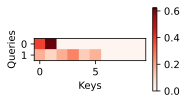

In [29]:
class AdditiveAttention(nn.Module):  
    """Additive attention."""
    def __init__(self, num_hiddens, dropout, **kwargs):
        super(AdditiveAttention, self).__init__(**kwargs)
        self.W_k = nn.LazyLinear(num_hiddens, bias=False)
        self.W_q = nn.LazyLinear(num_hiddens, bias=False)
        self.w_v = nn.LazyLinear(1, bias=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, queries, keys, values, valid_lens):
        queries, keys = self.W_q(queries), self.W_k(keys)

        # After dimension expansion (i.e. after unsqueeze), 
            # Shape of queries: (batch_size, no. of queries, 1, num_hiddens) 
            # Shape of keys:    (batch_size, 1, no. of key-value pairs, num_hiddens)
            # Sum them up with broadcasting
        features = torch.tanh(queries.unsqueeze(2) + keys.unsqueeze(1))

        # There is only one output of self.w_v, so we remove the last
        # one-dimensional entry from the shape. 
        # Shape of scores: (batch_size, no. of queries, no. of key-value pairs)
        scores = self.w_v(features).squeeze(-1)
        self.attention_weights = masked_softmax(scores, valid_lens)

        # Shape of values: (batch_size, no. of key-value pairs, value
        # dimension)
        return torch.bmm(self.dropout(self.attention_weights), values)
    
# Valid lengths is [2, 6], same as before
queries = torch.normal(0, 1, (2, 1, 20))

attention = AdditiveAttention(num_hiddens=8, dropout=0.1)
attention.eval()
d2l.check_shape(attention(queries, keys, values, valid_lens), (2, 1, 4))

d2l.show_heatmaps(attention.attention_weights.reshape((1, 1, 2, 10)),
                  xlabel='Keys', ylabel='Queries')

### 11.3.5 Summary
* 2 Key Attention Scoring Functions
    * Dot Product Attention 
        * Popular in modern transformer architectures
    * Additive Attention
        * More useful when queries and key vectors are of different lengths

### 11.3.6 Exercises
1. Implement distance-based attention by modifying the `DotProductAttention` code. Note that you only need the squared norms of the keys $\|\mathbf{k}_i\|^2$ for an efficient implementation. 
1. Modify the dot product attention to allow for queries and keys of different dimensionalities by employing a matrix to adjust dimensions. 
1. How does the computational cost scale with the dimensionality of the keys, queries, values, and their number? What about the memory bandwidth requirements?

Exercise #1
* Recall from earlier, Eqn. 11.3.1
$$ a(q, k_i) = -\frac{1}{2} \lVert q - k_i \rVert^2 = q^\top k_i - \frac{1}{2}\lVert k_i \rVert^2 - \frac{1}{2}\lVert q \rVert^2 $$
* Following same rationale as earlier, the norm of $q$ vector can be ignored, so like hint suggets, we only need to calculate norm of $k_i$ to get:
$$ a(q, k_i) = q^\top k_i - \frac{1}{2}\lVert k_i \rVert^2 $$
* Wouldn't use the scaling factor $\sqrt{d}$ in denominator

Exercise #2
* want a matrix of shape $a\times b$ to allow dot product between $Q\in \mathbb{R}^{n\times a}$ and $K^\top \in \mathbb{R}^{b\times m}$

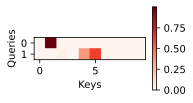

In [40]:
class DotProductAttention(nn.Module):
    """Copied from earlier to implement scaled dot product attention with matrix to ensure 
    key dimensions match query dimensions with matrix multiplication."""
    def __init__(self, dropout, query_dim, key_dim):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        self.M = torch.nn.parameter.Parameter(torch.randn(query_dim, key_dim))


    def forward(self, queries, keys, values, valid_lens=None):
        """
        Query Shape:      (batch_size, # of queries, a)
        Key Shape:        (batch_size, # of key-value pairs, b)
        Value Shape:      (batch_size, # of key-value pairs, value dim)
        Valid Lens Shape: (batch_size,) or (batch_size, # of queries)
        """
        a = queries.shape[-1]
        M_keys = torch.matmul(self.M, keys.transpose(1, 2))
        scores = torch.bmm(queries, M_keys) / math.sqrt(a)
        self.attention_weights = masked_softmax(scores, valid_lens)
        return torch.bmm(self.dropout(self.attention_weights), values)


# Output of full attention mechanism should be (batch_size, # of queries, value dim) = (2, 1, 4)
queries = torch.normal(0, 1, (2, 1, 4))
keys    = torch.normal(0, 1, (2, 10, 8))
values  = torch.normal(0, 1, (2, 10, 4))
valid_lens = torch.tensor([2, 6]) # valid lengths of 2, 6 for queries respectively

attention = DotProductAttention(dropout=0.2, query_dim=4, key_dim=8)
attention.eval()
d2l.check_shape(attention(queries, keys, values, valid_lens), (2, 1, 4))

d2l.show_heatmaps(attention.attention_weights.reshape((1, 1, 2, 10)),
                  xlabel='Keys', ylabel='Queries')

Exercise #3
* Computational cost scaling with dimensions of keys, queries, values?
* Assume same dimension between keys-queries for now = $d$
* Memory bandwidth requirements?
* Think in terms of minibatches for efficiency, such as calculating attention for $n$ queries and $m$ key-value pairs where the queries and keys are of length $d$ and values are of lenvth $v$
    * $Q\in \mathbb{R}^{n\times d}$
    * $K\in \mathbb{R}^{m\times d}$
    * $V\in \mathbb{R}^{m\times v}$
    * $ \text{softmax}\left( \frac{QK^\top}{\sqrt{d}} \right) V \in \mathbb{R}^{n\times v}$
* keep in mind, need to repeat for minibatch size B
* Dot product between q-k requires d multiplications, d-1 additions
* Scale by sqrt(d) to get another 1
* That was per attention score/scalar. Need to run that per query vector times number of key-value pairs, so n-times and m-times
* At this point, order of O(Bnmd) for attention score matrix. Need to weigh values by attention scores, so: $A\in \mathbb{R}^{n\times m} \times \mathbb{R}^{m\times v}$
    * per element of resultant $\mathbb{R}^{n\times v}$ matrix, needs order of $m$ multiplications + additions
    * Add batch asw
* Computational needs: $O(Bnmd + Bnmv)$
    * Realized I forgot calculations taht go into softmax operation itself
* Memory and thus memory bandwidth would scale $O(Bnm)$


# 11.4 The Bahdanau Attention Mechanism
* In Section 10.7, encountered encoder-decoder architecture for sequence-to-sequence learning based on two RNNs
* RNN Encoder: Transforms a variable-length sequence into a fixed-shape context variable
* RNN Decoder: Generates output (target) sequence token-by-token based on generated tokens and context variable

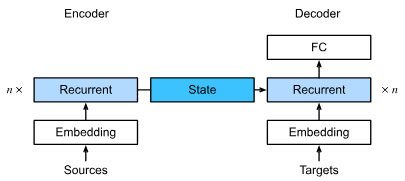

Conventionally in an RNN, all relevant informaiton about source sequence is transformed into fixed-dimensional state represented by encoder. Said state is used by decoder as only source of info for generating translated sequence i.e. the sequence-to-sequence mechanism treats the intermediate state as a sufficient statistics/source of whatever string might have served as input

* The sceheme above might be reasonmable and sufficient for short sequences, but infeasbile/insufficient for longer ones as the intermediate state may be insufficient to properly encode/store/represent the source sequence, and thus the decoder will fail for longer and complex sentences
* 2014 Bahdanau paper proposed differentiable attention model without unidirectional alignment limitation 
    * When predicting a token: In the case that not all input tokens are relevant, model aligns/attends only to parts of the input sequence that are deemed relevant to current prediction
    * This is then use to update the current state before generating the next token

In [41]:
import torch
from torch import nn
from d2l import torch as d2l

### 11.4.1 Model
* Use notation from Section 10.7
* Key idea is instead of keeping the state (i.e. context variable c that summarizes the source sentence) fixed, we dynamically update it, as a function of both the original text (encoder higgen states $h_t$) and the text that was already generated (decoder hidden states $s_{t'-1}$). 
    * This yields $c_{t'}$ which is updated after any decoding time step $t'$
* Suppose that the input sequence if of length $T$
    * Output of attention pooling: $ c_{t'} = \sum_{t=1}^T \alpha(s_{t'-1}, h_t)h_t$
    * $s_{t'-1}$ is the Query
    * $h_t$ as both the Key and Value
    * Note: $c_{t'}$ is used to generate state $s_{t'}$ and generate a new token
* Attention Scores are calculated with additive attention (rather than scaled dot product)
* Later, this RNN encoder-decoder architecture was modified to include the already generated token in decoder as further context (instead of the previously, just the state/context)

### 11.4.2 Defining the Decoder with Attention

In [43]:
class AttentionDecoder(d2l.Decoder):  #@save
    """The base attention-based decoder interface."""
    def __init__(self):
        super().__init__()

    @property
    def attention_weights(self):
        raise NotImplementedError

* Need to implement RNN decoder in Seq2SeqAttentionDecoder
* State is initialized with
    1. Hidden states of last layer of encoder at all time steps, to be used as keys and values for attention
    1. Hidden state of encoder at all layers during final time step, used to initialize hidden state of decoder
    1. Valid length of encoder, to exclude padding tokens in attention pooling. 
* At each decoding time step, the hidden state of final layer of decoder obtained at preious time step is used as query of attention mechanism
* Both (1) Output of Attention Mechanism and (2) Input Embedding are concatenated to serve as input to RNN decoder

In [49]:
class Seq2SeqAttentionDecoder(AttentionDecoder):
    """
    d2l.init_seq2seq: Sets nn.Linear and nn.GRU with Xavier initialization

    Args:
        num_hiddens: Dimension of hidden layer for additive attention"""
    def __init__(self, vocab_size, embed_size, num_hiddens, num_layers, dropout=0.0):
        super().__init__()
        self.attention = d2l.AdditiveAttention(num_hiddens, dropout)
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.rnn = nn.GRU(embed_size, num_hiddens, num_layers, dropout=dropout)
        self.dense = nn.LazyLinear(vocab_size)
        self.apply(d2l.init_seq2seq)


    def init_state(self, enc_outputs, enc_valid_lens):
        """
        Output Shape:       (num_steps,  batch_size, num_hiddens)
        hidden_state Shape: (num_layers, batch_size, num_hiddens)
        """
        outputs, hidden_state = enc_outputs
        # This instance of premute swaps first 2 dimensions
        return (outputs.permute(1, 0, 2), hidden_state, hidden_state, enc_valid_lens)
    

    def forward(self, X, state):
        """
        Forward pass for the attention-based decoder.
        
        Args:
            X: Input tensor of shape (batch_size, num_steps)
            state: Tuple containing:
                - enc_outputs: Encoder outputs of shape (batch_size, num_steps, num_hiddens)
                - hidden_state: Hidden state of shape   (num_layers, batch_size, num_hiddens)
                - enc_valid_lens: Valid lengths for encoder outputs
        
        Returns:
            outputs: Decoder outputs of shape (batch_size, num_steps, vocab_size)
            state:   Updated state for next forward pass
        """
        enc_outputs, hidden_state, enc_valid_lens = state
        
        X = self.embedding(X).permute(1, 0, 2)
        outputs, self._attention_weights = [], []
        
        for x in X:
            query = torch.unsqueeze(hidden_state[-1], dim=1)
            context = self.attention(query, enc_outputs, enc_outputs, enc_valid_lens)
            x = torch.cat((context, torch.unsqueeze(x, dim=1)), dim=-1)
            out, hidden_state = self.rnn(x.permute(1, 0, 2), hidden_state)
            outputs.append(out)
            self._attention_weights.append(self.attention.attention_weights)
        
        outputs = self.dense(torch.cat(outputs, dim=0))
        return outputs.permute(1, 0, 2), [enc_outputs, hidden_state, enc_valid_lens]
    
    @property
    def attention_weights(self):
        return self._attention_weights

In [45]:
vocab_size, embed_size, num_hiddens, num_layers = 10, 8, 16, 2
batch_size, num_steps = 4, 7
encoder = d2l.Seq2SeqEncoder(vocab_size, embed_size, num_hiddens, num_layers)
decoder = Seq2SeqAttentionDecoder(vocab_size, embed_size, num_hiddens,
                                  num_layers)
X = torch.zeros((batch_size, num_steps), dtype=torch.long)
state = decoder.init_state(encoder(X), None)
output, state = decoder(X, state)
d2l.check_shape(output, (batch_size, num_steps, vocab_size))
d2l.check_shape(state[0], (batch_size, num_steps, num_hiddens))
d2l.check_shape(state[1][0], (batch_size, num_hiddens))

### 11.4.3 Training

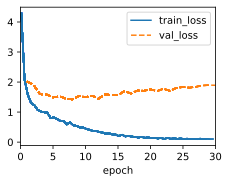

In [46]:
data = d2l.MTFraEng(batch_size=128)
embed_size, num_hiddens, num_layers, dropout = 256, 256, 2, 0.2
encoder = d2l.Seq2SeqEncoder(
    len(data.src_vocab), embed_size, num_hiddens, num_layers, dropout)
decoder = Seq2SeqAttentionDecoder(
    len(data.tgt_vocab), embed_size, num_hiddens, num_layers, dropout)
model = d2l.Seq2Seq(encoder, decoder, tgt_pad=data.tgt_vocab['<pad>'],
                    lr=0.005)
trainer = d2l.Trainer(max_epochs=30, gradient_clip_val=1, num_gpus=1)
trainer.fit(model, data)

In [47]:
engs = ['go .', 'i lost .', 'he\'s calm .', 'i\'m home .']
fras = ['va !', 'j\'ai perdu .', 'il est calme .', 'je suis chez moi .']
preds, _ = model.predict_step(
    data.build(engs, fras), d2l.try_gpu(), data.num_steps)
for en, fr, p in zip(engs, fras, preds):
    translation = []
    for token in data.tgt_vocab.to_tokens(p):
        if token == '<eos>':
            break
        translation.append(token)
    print(f'{en} => {translation}, bleu,'
          f'{d2l.bleu(" ".join(translation), fr, k=2):.3f}')

go . => ['va', '!'], bleu,1.000
i lost . => ["j'ai", 'perdu', '.'], bleu,1.000
he's calm . => ['je', "l'ai", 'vu', '.'], bleu,0.000
i'm home . => ['je', 'suis', 'chez', 'moi', '.'], bleu,1.000


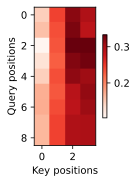

In [48]:
# Shows at each decoding step, different parts of input sequences are emphasized in attention pooling
_, dec_attention_weights = model.predict_step(
    data.build([engs[-1]], [fras[-1]]), d2l.try_gpu(), data.num_steps, True)
attention_weights = torch.cat(
    [step[0][0][0] for step in dec_attention_weights], 0)
attention_weights = attention_weights.reshape((1, 1, -1, data.num_steps))

# Plus one to include the end-of-sequence token
d2l.show_heatmaps(
    attention_weights[:, :, :, :len(engs[-1].split()) + 1].cpu(),
    xlabel='Key positions', ylabel='Query positions')

### 11.4.4 Summary
* When predicting the next token, if not all input tokens are relevant, the RNN encoder-decoder with Bahdanau attention mechanism selectively aggregates different parts of the input sequences
* This is achieved by treating the state (i.e. context variable) as an output of additive attentino pooling
* In RNN encoder-decoder, the attention mechanism treates the decoder hidden state at the previous time step as the query, and the encoder hidden states at all time steps as both the keys and values

### 11.4.5 Exercises
1. Replace GRU with LSTM in the experiment.
1. Modify the experiment to replace the additive attention scoring function with the scaled dot-product. How does it influence the training efficiency?

Exercise #1
* Replace GRU w/ LSTM

Exercise #2
* Replaced additive attentino with scaled dot product attention

# 11.5 Multi-Head Attention
* Given same set of queries, keys, and values we may want out model to combine knowledge from different behaviors of same attention mechanism (long-range vs short-range dependencies)
* Would be beneficial to allow attention mechanism to jointly use different representatino subspaces of Queries, Keys, and Values
* Instead of performing single attention pooling, Queries, Keys, Values can be transformed with $h$ independently learned linear projection
    * These projected Q, K, V's can be fed into attention pooling in parallel
    * At the end, the $h$ attention pooling outputs are concatenated and transformed with another learned linear projection to produce the final output
    * Called "multi-head attention", where each of the $h$ attention pooling outputs is called a "head"

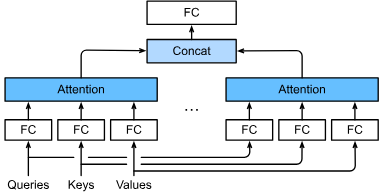

### 11.5.1 Model
* Given:
    * Query: $q\in \mathbb{R}^{d_q} $
    * Key: $ k \in \mathbb{R}^{d_k}$
    * Value: $v\in \mathbb{R}^{d_v}$
* And Learnable parameters/matricies:
    * $ W_i^q \in \mathbb{R}^{p_q \times d_q}$
    * $ W_i^k \in \mathbb{R}^{p_k \times d_k}$
    * $ W_i^v \in \mathbb{R}^{p_v \times d_v}$
* Each attention head $h_i$; $i=1,\dots, h$ can be computed as:
    * $ h_i = f(W_i^q q, W_i^k k, W_i^v v) \in \mathbb{R}^{p_v}$
    * Where $f$ is the attention pooling (say additive attention or scaled dot product attention)
* Then, the output of the multi-head attention output is obtained by another linear transformatin via learnable parameters/matrix: $W_o \in \mathbb{R}^{p_o \times hp_v}$
$$\mathbf W_o \begin{bmatrix}\mathbf h_1\\\vdots\\\mathbf h_h\end{bmatrix} \in \mathbb{R}^{p_o}.$$
* Suppposed to allow each head to attend to different parts of the input and allow more complexity than simple weighted average

### 11.5.2 Implementation
* Choose scaled dot product attention for each head of multi-head attention
* $p_q = p_k = p_v = p_o / h$: To avoid significant increase in computational cost
* NOTE: $h$ heads can be computed in parallel if we set the number of outputs of linear transformation for query, key, and value to: $p_q h = p_k h = p_v h = p_o$

In [58]:
class MultiHeadAttention(d2l.Module):
    def __init__(self, num_hiddens, num_heads, dropout, bias=False, **kwargs):
        super().__init__()
        self.num_heads = num_heads
        self.attention = d2l.DotProductAttention(dropout)
        self.W_q = nn.LazyLinear(num_hiddens, bias=bias)
        self.W_k = nn.LazyLinear(num_hiddens, bias=bias)
        self.W_v = nn.LazyLinear(num_hiddens, bias=bias)
        self.W_o = nn.LazyLinear(num_hiddens, bias=bias)


    def transpose_qkv(self, X):
        """
        Transpose queries, keys, or values for parallel computation of multiple attention heads.
        
        Input:  (batch_size,             seq_len, num_hiddens) 
        Output: (batch_size * num_heads, seq_len, num_hiddens / num_heads) 
        
        Args:
            X: Input tensor of shape (batch_size, seq_len, num_hiddens)
               where seq_len is the number of queries or key-value pairs,
               and num_hiddens must be divisible by num_heads.
        """
        X = X.reshape(X.shape[0], X.shape[1], self.num_heads, -1)
        X = X.permute(0, 2, 1, 3)
        return X.reshape(-1, X.shape[2], X.shape[3])

    def transpose_output(self, X):
        """Reverse the operation of transpose_qkv."""
        X = X.reshape(-1, self.num_heads, X.shape[1], X.shape[2])
        X = X.permute(0, 2, 1, 3)
        return X.reshape(X.shape[0], X.shape[1], -1)


    def forward(self, queries, keys, values, valid_lens):
        """
        Shape of queries, keys, or values:
        (batch_size, # of queries or key-value pairs, num_hiddens)

        Shape of valid_lens: (batch_size,) or (batch_size, # of queries)

        After transposing, shape of output queries, keys, or values:
        (batch_size * num_heads, # of queries or key-value pairs, num_hiddens / num_heads)
        """
        queries = self.transpose_qkv(self.W_q(queries))
        keys    = self.transpose_qkv(self.W_k(keys))
        values  = self.transpose_qkv(self.W_v(values))

        if valid_lens is not None:
            # On axis 0, copy the first item (scalar or vector) for num_heads
            # times, then copy the next item, and so on
            valid_lens = torch.repeat_interleave(valid_lens, repeats=self.num_heads, dim=0)

        # Shape of output: (batch_size * num_heads, # of queries,
        # num_hiddens / num_heads)
        output = self.attention(queries, keys, values, valid_lens)
        # Shape of output_concat: (batch_size, # of queries, num_hiddens)
        output_concat = self.transpose_output(output)
        return self.W_o(output_concat)
    

num_hiddens, num_heads = 100, 5
attention = MultiHeadAttention(num_hiddens, num_heads, 0.5)
batch_size, num_queries, num_kvpairs = 2, 4, 6
valid_lens = torch.tensor([3, 2])
X = torch.ones((batch_size, num_queries, num_hiddens))
Y = torch.ones((batch_size, num_kvpairs, num_hiddens))
d2l.check_shape(attention(X, Y, Y, valid_lens),
                (batch_size, num_queries, num_hiddens))

### 11.5.3 Summary
* Combines knowledge of same attention pooling via different representaiton subspaces of queries, keys, and values
* To compute the multi-head attention in parallel, make appropriate tensor manipulations

### 11.5.4 Exercises
1. Visualize attention weights of multiple heads in this experiment.
1. Suppose that we have a trained model based on multi-head attention and we want to prune less important attention heads to increase the prediction speed. How can we design experiments to measure the importance of an attention head?


Exercise #1

Exercise #2

# 11.6 Self-Attention and Positional Encoding
* imagine feeding a sequence of tokens into attention mechanism s.t. at every step, each token has its own query, keys, and values
* When computing the value of a token's representation at next layer, token can attend to any other token (by its query vector to matchings based on their key vectors)
* Using full set of query-key compatibility scores we can compute a representation by building the appropriate weighted sum over other tokens
* Because every token attends to every other token, they are called "self-attention models", unlike the case where the decoder steps attend to encoder steps

In [53]:
import math
import torch
from torch import nn
from d2l import torch as d2l

### 11.6.1 Self-Attention
* Given a sequence of input tokens $\mathbf{x}_1, \ldots, \mathbf{x}_n$ where any $\mathbf{x}_i \in \mathbb{R}^d$ ($1 \leq i \leq n$), its self-attention outputs a sequence of the same length $\mathbf{y}_1, \ldots, \mathbf{y}_n$, where

$$\mathbf{y}_i = f(\mathbf{x}_i, (\mathbf{x}_1, \mathbf{x}_1), \ldots, (\mathbf{x}_n, \mathbf{x}_n)) \in \mathbb{R}^d$$

* Using multi-head attention, the following code computes the self-attention of a tensor with shape (batch size, number of time steps or sequence length in tokens, $d$). The output tensor has the same shape.

In [59]:
num_hiddens, num_heads = 100, 5

attention = d2l.MultiHeadAttention(num_hiddens, num_heads, dropout=0.5)

batch_size, num_queries, valid_lens = 2, 4, torch.tensor([3, 2])

X = torch.ones((batch_size, num_queries, num_hiddens))

d2l.check_shape(attention(X, X, X, valid_lens), (batch_size, num_queries, num_hiddens))

### 11.6.2 Comparing CNNs, RNNs, and Self-Attention
* Consider a case of sequence of $n$ tokens to another one of equal length where each input and output token is represented by a $d$-dimensinal vector
* Note - sequential operations prevent parallel computations, while a shorter path between any combination of sequence positions makes it easier to learn long-range dependences within the sequence 

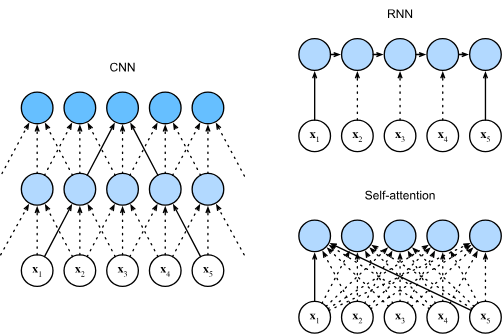

* CNNs
    * Consider any text sequence as a "one-dimensional image"
    * 1-dimensional CNNs can process local features such as $n$-grams in text
    * Given a sequence of length $n$, consider a convolutional layer whose kernel size is $k$ where input and output channels are both $d$ ($c_i = c_o = d$). 
    * Recall computational complexity of convolutional layer: $\mathcal{O}(knd^2)$
    * CNNs are hierarchical so there are $ \mathcal{O}(1)$ sequential operations and maximum path length is $ \mathcal{O}(n/k)$ 
        * e.g. $x_1$ and $x_5$ are within the receptive field of a 2-layer CNN w/ kernel size $3$
* RNNs
    * When updating hidden state of RNNs, multiplication of the $d\times d$ weight matrix and the $d$-dimensional hidden state has a computational complexity of $ \mathcal{O}(d^2)$
    * Given sequence length is $n$, the computational complexity of the recurrent layer is $\mathcal{O}(nd^2)$.
    * There are $\mathcal{O}(n)$ sequential operations that cannot be parallelized and the maximum path length is also $\mathcal{O}(n)$ 
* Self-Attention
    * Since self-attention, the queries, keys, and values are all $n\times d$ matricies
    * Consider scaled dot product attention - $n \times d$ matrix is multiplied by $d\times n$ matrix (for attention score), then the output is multiplied by a $n\times n$
    * Each token is directly connected to any other token via self-attention
    * Computation can be parallel with $\mathcal{O}(1)$ sequential operations and maximum path length is also $\mathcal{O}(1)$
* Takeaways
    * Both CNNs and self-attention enjoy parallel computation 
    * Self attention has shortest maximum path length
    * Self attentino has quadratic computational complexity w.r.t. sequence length, making slow and costly for long sequences

### 11.6.3 Positional Encoding
* RNNs recurrently process tokens of a sequence one-by-one
* Self-attention replaces sequential operations in favor of parallel computation
* Notice - self-attention does not inherently preserve order of sequence 
* Q: What if it matters which order the input sequence arrived in?
* A: Positional Encodings - (1) fixed a priori or (2) learned
* Suppose that the input representation $X\in \mathbb{R}^{n\times d}$ where $d$ corresponds to dimension of embedding and $n$ corresponds to token count of sequence
* Positional encoding outputs $X + P$ using positional embedding matrix $P\in \mathbb{R}^{n\times d}$ of same shape
    * Element on $i$-th row (which token it is) and the $(2j)$-th or $(2j+1)$-th columns is ($j$ corresponds to index along embedding dimension):
$$ p_{i, 2j}  = \sin{\frac{i}{10,000^{2j/d}}}$$
$$ p_{i, 2j+1}= \cos{\frac{i}{10,000^{2j/d}}}$$
* Positional embedding matrix $P$, rows correspond to positions in sequence and columns represent different positional encoding dimensions 
* In example plot below, see that the $6$ th and $7$ th columns of the positinoal embedding matrix have a higher frequency than the $8$ th and $9$ th columns due to alternation of sine and cosine waves

### 11.6.3.1 Absolute Positional Information 
* 

### 11.6.3.2 Relative Positional Information 
* Sinusoidal positional encoding also allows a model to easily learn to attend to relative positions
* This is because for any fixed positino offset $\delta$, the positional encoding at position $i + \delta$ can be represented by a linear projection of that at position $i$
* Notation 
    * $ w_j = 1/10000^{2j/d}$
    * Any pair of $(p_{i,2j}, p_{i, 2j+1})$ can be linearly projected to $ (p_{i+\delta, 2j}, p_{i+\delta, 2j + 1}) $ for a fixed offset $\delta$
$$\begin{aligned}
\begin{bmatrix} \cos(\delta \omega_j) & \sin(\delta \omega_j) \\  -\sin(\delta \omega_j) & \cos(\delta \omega_j) \\ \end{bmatrix}
\begin{bmatrix} p_{i, 2j} \\  p_{i, 2j+1} \\ \end{bmatrix}
=&\begin{bmatrix} \cos(\delta \omega_j) \sin(i \omega_j) + \sin(\delta \omega_j) \cos(i \omega_j) \\  -\sin(\delta \omega_j) \sin(i \omega_j) + \cos(\delta \omega_j) \cos(i \omega_j) \\ \end{bmatrix}\\
=&\begin{bmatrix} \sin\left((i+\delta) \omega_j\right) \\  \cos\left((i+\delta) \omega_j\right) \\ \end{bmatrix}\\
=& 
\begin{bmatrix} p_{i+\delta, 2j} \\  p_{i+\delta, 2j+1} \\ \end{bmatrix},
\end{aligned}$$

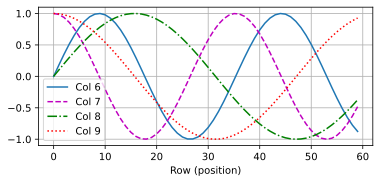

In [60]:
class PositionalEncoding(nn.Module):  
    """Relative Sinusoidal Positional encoding."""
    def __init__(self, num_hiddens, dropout, max_len=1000):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        # Create a long enough P
        self.P = torch.zeros((1, max_len, num_hiddens))
        X = torch.arange(max_len, dtype=torch.float32).reshape(-1, 1) / torch.pow(10000, torch.arange(0, num_hiddens, 2, dtype=torch.float32) / num_hiddens)
        self.P[:, :, 0::2] = torch.sin(X)
        self.P[:, :, 1::2] = torch.cos(X)

    def forward(self, X):
        X = X + self.P[:, :X.shape[1], :].to(X.device)
        return self.dropout(X)
    

encoding_dim, num_steps = 32, 60
pos_encoding = PositionalEncoding(encoding_dim, 0)
X = pos_encoding(torch.zeros((1, num_steps, encoding_dim)))
P = pos_encoding.P[:, :X.shape[1], :]
d2l.plot(torch.arange(num_steps), P[0, :, 6:10].T, xlabel='Row (position)', figsize=(6, 2.5), legend=["Col %d" % d for d in torch.arange(6, 10)])

### 11.6.4 Summary
* Self-attention: queries, keys, values all come from same place
* Both CNNs and self-attention enjoy benefits of parallel computation
* Self-attention has the shortest maximum path length
* Quadratic computational dependence w.r.t. sequence length makes self-attention prohibitively slow for very long sequences 
* Since self-attention on its own dosen't have any inherent knowledge of sequence/position, inject absolute or relative positional information by adding positional encodings to the input embedding representatino  

### 11.6.5 Exercises
1. Suppose that we design a deep architecture to represent a sequence by stacking self-attention layers with positional encoding. What could the possible issues be?
1. Can you design a learnable positional encoding method?
1. Can we assign different learned embeddings according to different offsets between queries and keys that are compared in self-attention? Hint: you may refer to relative position embeddings shaw2018self, huang2018music.


# 11.7 The Transformer Architecture

In [61]:
import math
import pandas as pd
import torch
from torch import nn
from d2l import torch as d2l

### 11.7.1 Model

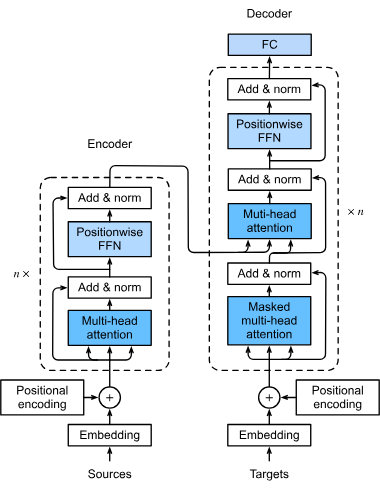

* Input (source) and Output (target) sequence embeddings are added with positional encoding before being fed into the encoder 
* $\textbf{Transformer Encoder}$: is stack of multiple identical layers, where each layer has 2 sublayers: (1) multi-head self-attention pooling (2) positionwise feed-forward network
* In the encoder: self-attention, queries, keys, and values are all outputs of the previous encoder layer
* Note - there is also a residual connection employed around both sublayers. Thus, in the Transformer for any input $x\in \mathbb{R}^d$ at any position of the sequence, we require that $\text{sublayer}(x) \in \mathbb{R}^d $ so that the residual connection $x + \text{sublayer}(x) \in \mathbb{R}^d$ is feasible. This is immediately followed by Layer Normalization layer. 
    * Thus, a transformer encoder outputs a $d$-dimensional vector representation for each position of the input sequence
* $\textbf{Transformer Decoder}$: Also a stack of multiple identical layers with residual connections and layer normalizations.
    * Along with the two sublayers in the encoder (multi-head self attention pooling, positionwise feed-forward network), there is a 3rd sublayer known as "encoder-decoder" attention between these two
* Encoder-Decoder Attention:
    * Queries from outputs of decoder's self-attention sublayer
    * Keys and Values are from the Transformer encoder outputs 
* Decoder Self-Attention:
    * Queries, Keys, Values are all from outputs of the previous decoder layer
    * Each position in the decoder is allowed only to attend to positions up to the current position. This is called _masked self-attention_ that preserves the autoregressive property, ensuring that the prediction only depends on those output tokens that have been generated

### 11.7.2 Positionwise Feed-Forward Networks
* Transforms representation at all sequence positions using the same MLP (hence its name, "positionwise")
* In the implementation below:
    * X (input): with the shape (batch_size, number_of_time_steps, num_hidden_units) will be transformed by a 2-layer MLP into an output tensor of shape (batch_size, number_of_time_steps, ffn_num_outputs)

In [62]:
class PositionWiseFFN(nn.Module):
    def __init__(self, ffn_num_hiddens, ffn_num_outputs):
        super().__init__()
        self.dense1 = nn.LazyLinear(ffn_num_hiddens)
        self.relu = nn.ReLU()
        self.dense2 = nn.LazyLinear(ffn_num_outputs)

    def forward(self, X):
        return self.dense2(self.relu(self.dense1(X)))

### 11.7.3 Residual Connection and Layer Normalization
* Focus on the "add & norm" component 
* Layer Normalization immediately follows the residual connection 
* Apparently, empirically batch normalization is less effective than layer normalization in natural language processing tasks (compared to computer vision), where the inputs are often variable-length sequences

In [64]:
class AddNorm(nn.Module):
    """Residual connection followed by layer normalization layer"""
    def __init__(self, normalized_shape, dropout=0.2):
        super().__init__()
        self.dropout   = nn.Dropout(dropout)
        self.LayerNorm = nn.LayerNorm(normalized_shape)

    def forward(self, X, Y):
        return self.LayerNorm(self.dropout(Y) + X)
    
    
# Residual connection requires same shape - check that it is so
add_norm = AddNorm(4, 0.5)
shape = (2, 3, 4)
d2l.check_shape(add_norm(torch.ones(shape), torch.ones(shape)), shape)

### 11.7.4 Encoder

In [65]:
class TransformerEncoderBlock(nn.Module):  
    """
    The Transformer encoder block. Contains 2 sublayers:
    1. Multi-head self-attention
    2. Position-wise feed-forward network

    Residual connection followed by layer normalization is employed around both sublayers. 
    """
    def __init__(self, num_hiddens, ffn_num_hiddens, num_heads, dropout, use_bias=False):
        super().__init__()
        self.attention = d2l.MultiHeadAttention(num_hiddens, num_heads, dropout, use_bias)
        self.addnorm1  = AddNorm(num_hiddens, dropout)
        self.ffn       = PositionWiseFFN(ffn_num_hiddens, num_hiddens)
        self.addnorm2  = AddNorm(num_hiddens, dropout)

    def forward(self, X, valid_lens):
        Y = self.addnorm1(X, self.attention(X, X, X, valid_lens))
        return self.addnorm2(Y, self.ffn(Y))
    

# Check that no layer in transformer encoder block changes the shape of its input
X = torch.ones((2, 100, 24))
valid_lens = torch.tensor([3, 2])
encoder_blk = TransformerEncoderBlock(24, 48, 8, 0.5)
encoder_blk.eval()
d2l.check_shape(encoder_blk(X, valid_lens), X.shape)

In [67]:
class TransformerEncoder(d2l.Encoder):  
    """The Transformer encoder."""
    def __init__(self, vocab_size, num_hiddens, ffn_num_hiddens, 
                 num_heads, num_blks, dropout, use_bias=False):
        super().__init__()
        self.num_hiddens  = num_hiddens
        self.embedding    = nn.Embedding(vocab_size, num_hiddens)
        self.pos_encoding = d2l.PositionalEncoding(num_hiddens, dropout)
        self.blks = nn.Sequential()
        
        for i in range(num_blks):
            self.blks.add_module("block"+str(i), TransformerEncoderBlock(
                num_hiddens, ffn_num_hiddens, num_heads, dropout, use_bias))

    def forward(self, X, valid_lens):
        """
        Since positional encoding values are between -1 and 1, the embedding
        values are multiplied by the square root of the embedding dimension to
        rescale before they are summed up.
        """
        X = self.pos_encoding(self.embedding(X) * math.sqrt(self.num_hiddens))
        self.attention_weights = [None] * len(self.blks)
        for i, blk in enumerate(self.blks):
            X = blk(X, valid_lens)
            self.attention_weights[i] = blk.attention.attention.attention_weights
        return X
    
# Transformer Encoder output shape: (batch_size, number_of_time_steps, num_hidden)
encoder = TransformerEncoder(200, 24, 48, 8, 2, 0.5)
d2l.check_shape(encoder(torch.ones((2, 100), dtype=torch.long), valid_lens), (2, 100, 24))

### 11.7.5 Decoder

In [68]:
class TransformerDecoderBlock(nn.Module):
    """The i-th block in the Transformer decoder"""
    def __init__(self, num_hiddens, ffn_num_hiddens, num_heads, dropout, i):
        super().__init__()
        self.i = i
        self.attention1 = d2l.MultiHeadAttention(num_hiddens, num_heads, dropout)
        self.addnorm1   = AddNorm(num_hiddens, dropout)
        self.attention2 = d2l.MultiHeadAttention(num_hiddens, num_heads, dropout)
        self.addnorm2   = AddNorm(num_hiddens, dropout)
        self.ffn        = PositionWiseFFN(ffn_num_hiddens, num_hiddens)
        self.addnorm3   = AddNorm(num_hiddens, dropout)

    def forward(self, X, state):
        enc_outputs, enc_valid_lens = state[0], state[1]
        # During training, all the tokens of any output sequence are processed
        # at the same time, so state[2][self.i] is None as initialized. When
        # decoding any output sequence token by token during prediction,
        # state[2][self.i] contains representations of the decoded output at
        # the i-th block up to the current time step
        if state[2][self.i] is None:
            key_values = X
        else:
            key_values = torch.cat((state[2][self.i], X), dim=1)
        state[2][self.i] = key_values
        if self.training:
            batch_size, num_steps, _ = X.shape
            # Shape of dec_valid_lens: (batch_size, num_steps), where every
            # row is [1, 2, ..., num_steps]
            dec_valid_lens = torch.arange(
                1, num_steps + 1, device=X.device).repeat(batch_size, 1)
        else:
            dec_valid_lens = None
        # Self-attention
        X2 = self.attention1(X, key_values, key_values, dec_valid_lens)
        Y = self.addnorm1(X, X2)
        # Encoder-decoder attention. Shape of enc_outputs:
        # (batch_size, num_steps, num_hiddens)
        Y2 = self.attention2(Y, enc_outputs, enc_outputs, enc_valid_lens)
        Z = self.addnorm2(Y, Y2)
        return self.addnorm3(Z, self.ffn(Z)), state
    
decoder_blk = TransformerDecoderBlock(24, 48, 8, 0.5, 0)
X = torch.ones((2, 100, 24))
state = [encoder_blk(X, valid_lens), valid_lens, [None]]
d2l.check_shape(decoder_blk(X, state)[0], X.shape)

In [69]:
class TransformerDecoder(d2l.AttentionDecoder):
    def __init__(self, vocab_size, num_hiddens, ffn_num_hiddens, num_heads,
                 num_blks, dropout):
        super().__init__()
        self.num_hiddens = num_hiddens
        self.num_blks = num_blks
        self.embedding = nn.Embedding(vocab_size, num_hiddens)
        self.pos_encoding = d2l.PositionalEncoding(num_hiddens, dropout)
        self.blks = nn.Sequential()
        for i in range(num_blks):
            self.blks.add_module("block"+str(i), TransformerDecoderBlock(
                num_hiddens, ffn_num_hiddens, num_heads, dropout, i))
        self.dense = nn.LazyLinear(vocab_size)

    def init_state(self, enc_outputs, enc_valid_lens):
        return [enc_outputs, enc_valid_lens, [None] * self.num_blks]

    def forward(self, X, state):
        X = self.pos_encoding(self.embedding(X) * math.sqrt(self.num_hiddens))
        self._attention_weights = [[None] * len(self.blks) for _ in range (2)]
        for i, blk in enumerate(self.blks):
            X, state = blk(X, state)
            # Decoder self-attention weights
            self._attention_weights[0][
                i] = blk.attention1.attention.attention_weights
            # Encoder-decoder attention weights
            self._attention_weights[1][
                i] = blk.attention2.attention.attention_weights
        return self.dense(X), state

    @property
    def attention_weights(self):
        return self._attention_weights

### 11.7.6 Training

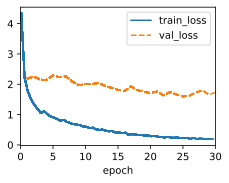

In [ ]:
data = d2l.MTFraEng(batch_size=128)
num_hiddens, num_blks, dropout = 256, 2, 0.2
ffn_num_hiddens, num_heads = 64, 4
encoder = TransformerEncoder(len(data.src_vocab), num_hiddens, ffn_num_hiddens, num_heads, num_blks, dropout)
decoder = TransformerDecoder( len(data.tgt_vocab), num_hiddens, ffn_num_hiddens, num_heads, num_blks, dropout)
model = d2l.Seq2Seq(encoder, decoder, tgt_pad=data.tgt_vocab['<pad>'], lr=0.001)
trainer = d2l.Trainer(max_epochs=30, gradient_clip_val=1, num_gpus=1)
trainer.fit(model, data)

In [71]:
engs = ['go .', 'i lost .', 'he\'s calm .', 'i\'m home .']
fras = ['va !', 'j\'ai perdu .', 'il est calme .', 'je suis chez moi .']
preds, _ = model.predict_step(
    data.build(engs, fras), d2l.try_gpu(), data.num_steps)
for en, fr, p in zip(engs, fras, preds):
    translation = []
    for token in data.tgt_vocab.to_tokens(p):
        if token == '<eos>':
            break
        translation.append(token)
    print(f'{en} => {translation}, bleu,'
          f'{d2l.bleu(" ".join(translation), fr, k=2):.3f}')

go . => ['va', '!'], bleu,1.000
i lost . => ["j'ai", 'perdu', '.'], bleu,1.000
he's calm . => ['il', 'est', 'mouillé', '.'], bleu,0.658
i'm home . => ['je', 'suis', 'chez', 'moi', '.'], bleu,1.000


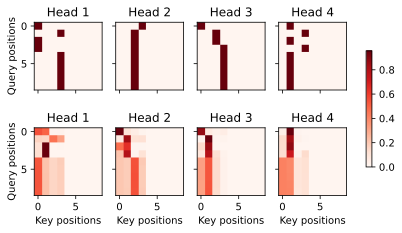

In [72]:
_, dec_attention_weights = model.predict_step(
    data.build([engs[-1]], [fras[-1]]), d2l.try_gpu(), data.num_steps, True)
enc_attention_weights = torch.cat(model.encoder.attention_weights, 0)
shape = (num_blks, num_heads, -1, data.num_steps)
enc_attention_weights = enc_attention_weights.reshape(shape)
d2l.check_shape(enc_attention_weights,
                (num_blks, num_heads, data.num_steps, data.num_steps))

d2l.show_heatmaps(
    enc_attention_weights.cpu(), xlabel='Key positions',
    ylabel='Query positions', titles=['Head %d' % i for i in range(1, 5)],
    figsize=(7, 3.5))

In [74]:
dec_attention_weights_2d = [head[0].tolist()
                            for step in dec_attention_weights
                            for attn in step for blk in attn for head in blk]
dec_attention_weights_filled = torch.tensor(
    pd.DataFrame(dec_attention_weights_2d).fillna(0.0).values)
shape = (-1, 2, num_blks, num_heads, data.num_steps)
dec_attention_weights = dec_attention_weights_filled.reshape(shape)
dec_self_attention_weights, dec_inter_attention_weights = \
    dec_attention_weights.permute(1, 2, 3, 0, 4)

d2l.check_shape(dec_self_attention_weights,
                (num_blks, num_heads, data.num_steps, data.num_steps))
d2l.check_shape(dec_inter_attention_weights,
                (num_blks, num_heads, data.num_steps, data.num_steps))

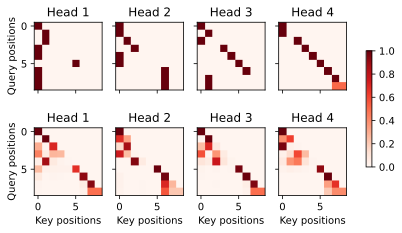

In [75]:
d2l.show_heatmaps(
    dec_self_attention_weights[:, :, :, :],
    xlabel='Key positions', ylabel='Query positions',
    titles=['Head %d' % i for i in range(1, 5)], figsize=(7, 3.5))

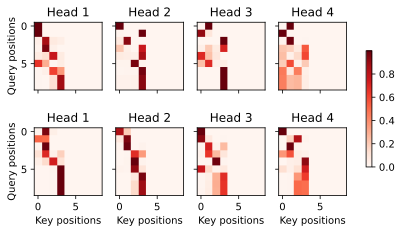

In [ ]:
d2l.show_heatmaps(
    dec_inter_attention_weights, xlabel='Key positions',
    ylabel='Query positions', titles=['Head %d' % i for i in range(1, 5)],
    figsize=(7, 3.5))

### 11.7.7 Summary
* Original Transformer is an instance of encoder-decoder architecture
* In practice, encoder or decoder can used individually in practice
* In the Transformer architecture, multi-head self-attention is used for representing the input sequence and the output sequence
    * Decoder has to preserve autoregressive property via a masked version
* Both residual connection and layer normalization in Transformer are important for training a very deep model
* Positionwise Feed-Forward network in the Transformer model transforms the representation at all sequence positions using the same MLP

### 11.7.8 Exercises
1. Train a deeper Transformer in the experiments. How does it affect the training speed and the translation performance?
1. Is it a good idea to replace scaled dot product attention with additive attention in the Transformer? Why?
1. For language modeling, should we use the Transformer encoder, decoder, or both? How would you design this method?
1. What challenges can Transformers face if input sequences are very long? Why?
1. How would you improve the computational and memory efficiency of Transformers? Hint: you may refer to the survey paper by Tay.Dehghani.Bahri.ea.2020.


# 11.8 Transformers for Vision
* Extract patches from images and feed them into a Transformer encoder to obtain a global representation
* Said global representation will be transformed for classification
* Transformers show better scalability than CNNs
* When training larger models on larger datasets, Vision Transformers outperform ResNets by a significant margin

In [77]:
import torch
from torch import nn
from d2l import torch as d2l

### 11.8.1 Model


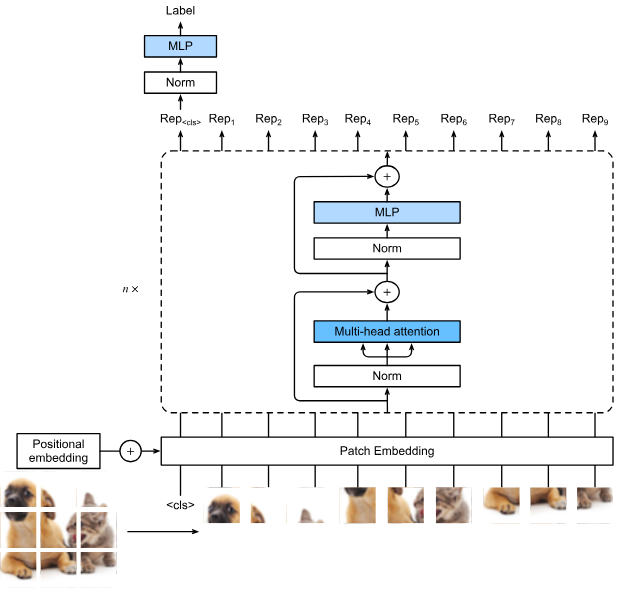

* The vision Transformer architecture. In this example, an image is split into nine patches. A special “<cls>” token and the nine flattened image patches are transformed via patch embedding and 
 Transformer encoder blocks into ten representations, respectively. The “<cls>” representation is further transformed into the output label.¶
* Consider an input image with height $h$, width $w$, and $c$ channels where we specify the patch height and width both as $p$, thus the image is split into a sequence of $m = hw/p^2$ patches, where each patch is flattened to a vector of length $cp^2$.
* In this way, image patches can be treated similarly to tokens in text sequences by Transformer encoders.
* A special “&lt;cls&gt;” (class) token and the $m$ flattened image patches are linearly projected into a sequence of $m+1$ vectors, summed with learnable positional embeddings. The multilayer Transformer encoder transforms $m+1$ input vectors into the same number of output vector representations of the same length.
* Note, this works exactly the same way as the original Transformer encoder, only differing in the position of normalization.
* Since the “&lt;cls&gt;” token attends to all the image patches via self-attention its representation from the Transformer encoder output will be further transformed into the output label.

### 11.8.2 Patch Embedding
* Splitting an image into patches and linearly projecting these flattened patches can be simplified as a single convoltion operation, where both kernel size and stride size are set to the patch size

In [83]:
class PatchEmbedding(nn.Module):
    def __init__(self, img_size=96, patch_size=16, num_hiddens=512):
        super().__init__()

        def _make_tuple(x):
            if not isinstance(x, (list, tuple)):
                return (x, x)
            return x
        
        img_size   = _make_tuple(img_size)
        patch_size = _make_tuple(patch_size)
        # //: Floor Division that rounds down result to nearest whole number
        self.num_patches = (img_size[0] // patch_size[0]) * (img_size[1] // patch_size[1])
        self.conv = nn.LazyConv2d(num_hiddens, kernel_size=patch_size, stride=patch_size)

    def forward(self, X):
        # Input:           (batch_size, num_channels, patch_rows, patch_columns)
        # Flatten(2):      (batch_size, num_channels, patch_rows * patch_columns)  - Flattens everything dim2 and beyond since 2 is passed as start_dim
        # Transpose(1, 2): (batch_size, patch_rows * patch_columns, num_channels)

        # Output shape:        (batch size, no. of patches, no. of channels)
        # CNN Expects:         (batch_size, num_channels, height, width)
        # Transformer expects: (batch, sequence_length, embedding_dim)
        return self.conv(X).flatten(start_dim=2).transpose(1, 2)

In [81]:
x = [1, 2, 3]
test1 = isinstance(x, list)
test2 = isinstance(x, (list, tuple))
print(test1, test2)

True True


In [86]:
img_size, patch_size, num_hiddens, batch_size = 96, 16, 512, 4

patch_emb = PatchEmbedding(img_size, patch_size, num_hiddens)

X = torch.zeros(batch_size, 3, img_size, img_size)

d2l.check_shape(patch_emb(X), (batch_size, (img_size//patch_size)**2, num_hiddens))

### 11.8.3 Vision Transformer Encoder

* MLP of ViT encoder is slighly different than positionwise FFN of original Transformer encoder. 
    * ViT uses activation function of Gaussian Error Linear Unit (GELU) which can be considered as a smoother version of the ReLU
    * Dropout is applied to output of each fully connected layer in the MLP for regularization 

In [ ]:
class ViTMLP(nn.Module):
    def __init__(self, mlp_num_hiddens, mlp_num_outputs, dropout=0.5):
        super().__init__()
        self.dense1 = nn.LazyLinear(mlp_num_hiddens)
        self.gelu = nn.GELU()
        self.dropout1 = nn.Dropout(dropout)
        self.dense2 = nn.LazyLinear(mlp_num_outputs)
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout2(self.dense2(self.dropout1(self.gelu(self.dense1(x)))))

* ViT encoder block implementation follows pre-normalization design where normalization is applied right before the multi-head attention (or MLP)
* In contrast to post-normalizatio ("add & norm"), where normalization is placed right after residual connections, pre-normalization leads to more effective/efficient training for Transformers 
* CHECK THE 3 SOURCES POSTED LATER... https://d2l.ai/chapter_attention-mechanisms-and-transformers/vision-transformer.html 

In [ ]:
class ViTBlock(nn.Module):
    def __init__(self, num_hiddens, norm_shape, mlp_num_hiddens,
                 num_heads, dropout, use_bias=False):
        super().__init__()
        self.ln1 = nn.LayerNorm(norm_shape)
        self.attention = d2l.MultiHeadAttention(num_hiddens, num_heads, dropout, use_bias)
        self.ln2 = nn.LayerNorm(norm_shape)
        self.mlp = ViTMLP(mlp_num_hiddens, num_hiddens, dropout)

    def forward(self, X, valid_lens=None):
        X = X + self.attention(*([self.ln1(X)] * 3), valid_lens)
        return X + self.mlp(self.ln2(X))
    
# Verification that no ViT encoder block changes its shape
X = torch.ones((2, 100, 24))
encoder_blk = ViTBlock(24, 24, 48, 8, 0.5)
encoder_blk.eval()
d2l.check_shape(encoder_blk(X), X.shape)

### 11.8.4 Putting It All Together

Forward pass of Vision Transformer
1. Input images are fed into an PatchEmbedding instance, whose output is concatenated with the "<cls>" token embedding
1. They are summed with learnable positional embeddings before dropout
1. Output is fed into the Transformer encoder that stacks _num_blks_ instances of the _VitBlock_ class
1. Finally, the representation of the "<cls>" token is projected by the network head

In [90]:
class ViT(d2l.Classifier):
    """Vision Transformer."""
    def __init__(self, img_size, patch_size, num_hiddens, mlp_num_hiddens,
                 num_heads, num_blks, emb_dropout, blk_dropout, lr=0.1,
                 use_bias=False, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.patch_embedding = PatchEmbedding(
            img_size, patch_size, num_hiddens)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, num_hiddens))
        num_steps = self.patch_embedding.num_patches + 1  # Add the cls token
        # Positional embeddings are learnable
        self.pos_embedding = nn.Parameter(
            torch.randn(1, num_steps, num_hiddens))
        self.dropout = nn.Dropout(emb_dropout)
        self.blks = nn.Sequential()
        for i in range(num_blks):
            self.blks.add_module(f"{i}", ViTBlock(
                num_hiddens, num_hiddens, mlp_num_hiddens,
                num_heads, blk_dropout, use_bias))
        self.head = nn.Sequential(nn.LayerNorm(num_hiddens),
                                  nn.Linear(num_hiddens, num_classes))

    def forward(self, X):
        X = self.patch_embedding(X)
        X = torch.cat((self.cls_token.expand(X.shape[0], -1, -1), X), 1)
        X = self.dropout(X + self.pos_embedding)
        for blk in self.blks:
            X = blk(X)
        return self.head(X[:, 0])

### 11.8.5 Training

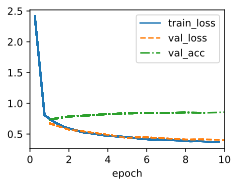

In [91]:
img_size, patch_size = 96, 16
num_hiddens, mlp_num_hiddens, num_heads, num_blks = 512, 2048, 8, 2
emb_dropout, blk_dropout, lr = 0.1, 0.1, 0.1
model = ViT(img_size, patch_size, num_hiddens, mlp_num_hiddens, num_heads,
            num_blks, emb_dropout, blk_dropout, lr)
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(img_size, img_size))
trainer.fit(model, data)

### 11.8.6 Summary and Discussion
* For small datasets like FashionMnist, implemented version of ViT does not outperform ResNet, and similar observations/trends hold for ImageNet dataset
* Presumed to be because Transformers lack inductive biases present in convolution (locality, translational invariance), and thus requires larger datasets to allow it to learn these biases from data
* On larger datasets (e.g. 300M images), ViTs outperform ResNets by a large margin in image classification, demonstrating superior scalability
* Quadratic complexity of self-attention makes Transformer less suitable for higher-resolution images
* Swin-Transformers address quadractic computational complexity w.r.t. image size by reinstated convolution-like priors

### 11.8.7 Exercises
1. How does the value of `img_size` affect training time?
1. Instead of projecting the “&lt;cls&gt;” token representation to the output, how would you project the averaged patch representations? Implement this change and see how it affects the accuracy.
1. Can you modify hyperparameters to improve the accuracy of the vision Transformer?


# 11.9 Large-Scale Pretraining with Transformers

* Encoder-Only
* Encoder-Decoder
* Decoder-Only

### 11.9.1 Encoder-Only
* Sequence of input tokens is converted into same number of representations that can be further projected into output (e.g. classification)
* Consists of self-attentino layers where all input tokens attend to each other
* For Example, ViT's are encoder-only, converting a sequence of input image patches into the representation of a special "cls" token
* Since this representation depends on all input tokens (by self-attention), it is further projected into classification labels
* This design is inspired from early encoder-only Transformer pretrained on text: BERT (Bidirectional Encoder Representations from Transformers)

### 11.9.1.1 Pretraining BERT

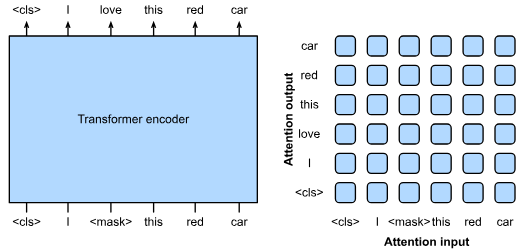

* Left: Pretraining BERT with masked language modeling. Prediction of the masked “love” token depends on all input tokens before and after “love”. 
* Right: Attention pattern in the Transformer encoder. Each token along the vertical axis attends to all input tokens along the horizontal axis. 
* BERT is pretrained on masked language modeling
    * Input text with randomly masked tokens is fed into Transformer encoder to predict the masked tokens
    * Original text sequence of: "I love this red car" is prepended with the "cls" token and the "mask" token will randomly replace "love" (in this instance). 
    * The cross-entropy loss between the masked-token "love" and its prediction (given by the encoder) is minimized during pretraining
    * Note - there is no constraint in the attention pattern of Transformer encoders, and thus all tokens can attend to each other. In this instance, to predict "love" (that is masked), Transformer encoder can depend on input tokens before and after it in the sequence - hence its namesake "bidirectional encoder"
    * This training scheme does not need manual labeling, and large-scale text data from books and Wikipedia can be used for pretraining BERT

### 11.9.1.2 Fine-Tuning BERT
* Pretrained BERT can be fine-tuned for downstream encoding tasks involving single text or text pairs
* During fine-tuning, additional layers can be added to BERT with randomized parameters - these parameters and those pretrained BERT parameters will be updated to fit training data of downstream tasks

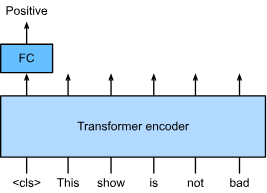
* Fine-tuning BERT for sentiment analysis
* Transformer encoder is a pretrained BERT, which takes a text sequence as input and feeds the "clas" representation (the global representation of the input) into an additional FC layer to predict the sentimant
* During fine-tuning, the cross-entropy loss between the prediction and label on sentiment analysis data is minimized via gradient-based algorithims, where additional layer is trained from scratch while pretrained prameters of BERT are updated
* Note, BERT is not restricted to sentiment analysis, also could fine-tune it do to single-text classification, text-pair classification/regression, text-tagging, question answering

### 11.9.2 Encoder–Decoder
* Since Transformer encoder converts a sequence of input tokens into same number of output representations, the encoder-only mode cannot generate a sequence of arbitrary length (say for machine translation)
* Originally proposed for machine translation, the Transformrer architecture can be outfitted with decoder that autoregressively predicts the target sequence of arbitrary length, token-by-tokne, conditional on both encoder and decoder ouput
    1. For conditioning on encoder output, encoder-decoder cross-attention (multi-head attention of decoder) allows target tokens to attend to all input tokens
    1. Conditional on decoder output is achieved by achieved "causal attention pattern" (note - name is a bit misleading as it does not have anything to do with the proper study of causality in ML) where any target token can only attend to past and present tokens in target sequence (unlike BERT where it can attend to all past, present, and future tokens that are unmasked)
* To pretrain Encoder-Decoder Transformers, BART and T5 were proposed (both able to train beyond human-labeled machine translation data) that are both pretrained on large scale text corpora
    * Both attempt to reconstruct original text in their pretraining objectives, while the former emphasizes noising input (e.g. masking, deletion, permutation, rotation)

### 11.9.2.1 Pretraining T5
* As an example of pretrained Transformer Encoder-Decoder, T5 (Text-to-Text Transfer Transformer) unifies many tasks as the same text-to-text problem
    * For any task, the input of the encoder is a task description (e.g. "Summarize", ":") followed by the task input (e.g. sequence of tokens from an article), and the decoder predicts the task output (e.g. a sequence of tokens summarizing the input article)
    * To perform as text-to-text, T5 is trained to generate some target text conditional on input text

### 11.9.2.2 Fine-Tuning T5
* Similar to BERT, T5 needs to be fine-tuned (ipdating T5 parameters) on task-specific training data to perform this task
* Major differences from BERT fine-tuning such as:
    1. T5 input includes task descriptions
    1. T5 can generate sequences with arbitrary length with its Transformer decoder
    1. No additional layers are required
* After fine-tuning, the 11 billion parameter T5 (T5-11B) achieved SOTA results on multiple encoding (e.g. classification) and generatino (e.g. summarization) tasks/benchmarks
* T5 has been used extensively for research such as:
    * Switch Transformers to activate a subset of parameters for better computational efficiency
    * Text-to-Image model called Imagen, where text is input to a frozen T5 encoder (T5-XXL) with 4.6 billion parameters

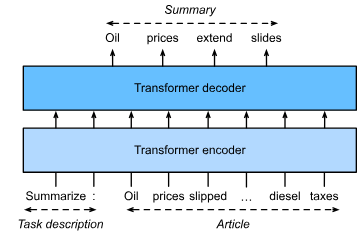
* Fine-tuning T5 for text summarization. Both the task description and article tokens are fed into the Transformer encoder for predicting the summary.

### 11.9.3 Decoder Only
* As its name indicates, remove entire encoder and decoder sublayer with encoder-decoder cross-attention from original encoder-decoder architecture
* Nowadays, the de-facto architecture in large-scale language modeling where it can take advantage of abundant unlabeled text corpora via self-supervised learning

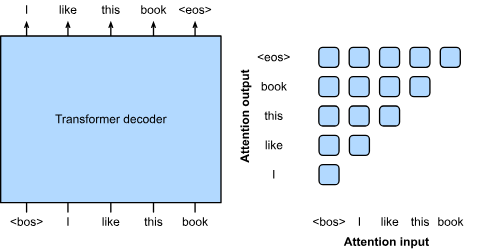
* Left: Pretraining GPT with language modeling. The target sequence is the input sequence shifted by one token. Both “<bos>” and “<eos>” are special tokens marking the beginning and end of sequences, respectively. 
* Right: Attention pattern in the Transformer decoder. Each token along the vertical axis attends to only its past tokens along the horizontal axis (causal).
* Following autoregressive language modeling, above figure illustrates GPT pretraining with Transformer encoder where target sequence is input sequence shifted by one token
* Note - attention pttern in decoder-only Transformer architecture requires that each token can attend to only its past tokens 
* Larger scale decoder-only Transformers (GPT-2) showed promising results on langauge modeling benchmarks on multiple tasks without updating paramters or architecture
* Potential for using same language model for multiple tasks without updating the model
* In-Context Learning
    * Zero-Shot: No task-specific input-output examples
    * One-Shot:  One task-specific input-output example
    * Few-Shot:  Multipole task-specific input-output examples

### 11.9.3 Decoder-Only

### 11.9.4 Scalability

### 11.9.5 Large Language Models

### 11.9.6 Summary and Discussion

### 11.9.7 Exercises
1. Is it possible to fine-tune T5 using a minibatch consisting of different tasks? Why or why not? How about for GPT-2?
1. Given a powerful language model, what applications can you think of?
1. Say that you are asked to fine-tune a language model to perform text classification by adding additional layers. Where will you add them? Why?
1. Consider sequence-to-sequence problems (e.g., machine translation) where the input sequence is always available throughout the target sequence prediction. What could be limitations of modeling with decoder-only Transformers? Why?

